# Overlapping Mitigation

### <i> Using TomeKLinks, SmoteTomek, ClusterCentroids

In [47]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("../lifestyle_sustainability_data_processed.csv")
df

,Age,LocalFoodFrequency,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,UsingPlasticProducts,...,EnergySource_Mixed,EnergySource_Non-Renewable,HomeType_Apartment,HomeType_House,Gender_Female,Gender_Male,Gender_Non-Binary,DisposalMethods_Combination,DisposalMethods_Composting,DisposalMethods_Landfill
0,35,2,800,0,1,5,2.0,100,1500,1,...,0,0,1,0,1,0,0,0,1,0
1,28,1,1500,1,1,4,1.0,250,3000,2,...,1,0,0,1,0,1,0,0,0,0
2,65,0,2500,2,0,2,0.0,400,4500,3,...,0,1,0,1,0,1,0,0,0,1
3,42,2,950,1,1,4,1.0,150,2000,1,...,0,0,1,0,1,0,0,0,0,0
4,31,1,1800,2,1,3,0.0,300,3500,2,...,1,0,0,1,0,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
494,38,2,1789,1,1,4,2.0,150,2000,1,...,0,0,0,1,1,0,0,0,0,0
495,25,1,987,2,0,2,0.0,400,4500,3,...,0,1,1,0,0,1,0,0,0,1
496,51,3,1678,0,1,5,2.0,280,3200,2,...,1,0,0,1,0,0,1,0,0,0
497,32,0,1850,2,0,1,2.0,397,4076,1,...,1,0,0,1,1,0,0,0,0,0


In [49]:
df.head()

,Age,LocalFoodFrequency,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,UsingPlasticProducts,...,EnergySource_Mixed,EnergySource_Non-Renewable,HomeType_Apartment,HomeType_House,Gender_Female,Gender_Male,Gender_Non-Binary,DisposalMethods_Combination,DisposalMethods_Composting,DisposalMethods_Landfill
0,35,2,800,0,1,5,2.0,100,1500,1,...,0,0,1,0,1,0,0,0,1,0
1,28,1,1500,1,1,4,1.0,250,3000,2,...,1,0,0,1,0,1,0,0,0,0
2,65,0,2500,2,0,2,0.0,400,4500,3,...,0,1,0,1,0,1,0,0,0,1
3,42,2,950,1,1,4,1.0,150,2000,1,...,0,0,1,0,1,0,0,0,0,0
4,31,1,1800,2,1,3,0.0,300,3500,2,...,1,0,0,1,0,0,1,1,0,0


<Axes: xlabel='Age', ylabel='EnvironmentalAwareness'>

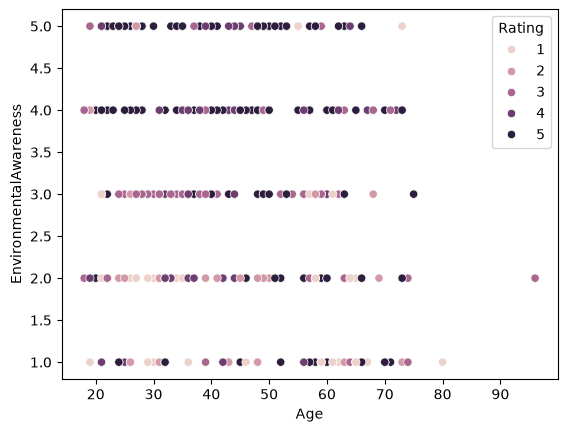

In [50]:
# Now let's take a particularly nasty overlap. Here.
sns.scatterplot(df, x="Age", y="EnvironmentalAwareness", hue="Rating")

# In real life, does this overlap seem feasable? Probably.
# There's always some overlap (especially in health diagnosis data).

# But say this didn't reflect reality and there's some reason to 
# fix the overlap (to which there are many)...

---

### Encoding

In [51]:
# # Binary encoding the `diabetes` column
# variables = ['diabetes']

# df[variables] = df[variables].replace({
#     'neg': 0,
#     'pos': 1
# })

---

### TomeKLinks

In [52]:
from imblearn.under_sampling import TomekLinks

df = df.dropna()

# X y split to prevent data leakage
X = df.drop(columns="Rating", axis=1)
y = df["Rating"]

# Let's use vanilla tomeklinks
tomek = TomekLinks()

# Fit and resample.
X_resampled, y_resampled = tomek.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["Rating"] = y_resampled
df_resampled

,Age,LocalFoodFrequency,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,UsingPlasticProducts,...,EnergySource_Non-Renewable,HomeType_Apartment,HomeType_House,Gender_Female,Gender_Male,Gender_Non-Binary,DisposalMethods_Combination,DisposalMethods_Composting,DisposalMethods_Landfill,Rating
0,35,2,800,0,1,5,2.0,100,1500,1,...,0,1,0,1,0,0,0,1,0,5
1,28,1,1500,1,1,4,1.0,250,3000,2,...,0,0,1,0,1,0,0,0,0,4
2,65,0,2500,2,0,2,0.0,400,4500,3,...,1,0,1,0,1,0,0,0,1,1
3,42,2,950,1,1,4,1.0,150,2000,1,...,0,1,0,1,0,0,0,0,0,5
4,31,1,1800,2,1,3,0.0,300,3500,2,...,0,0,1,0,0,1,1,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
282,64,1,654,2,0,2,0.0,400,4500,3,...,1,0,0,0,1,0,0,0,1,1
283,38,2,1789,1,1,4,2.0,150,2000,1,...,0,0,1,1,0,0,0,0,0,4
284,25,1,987,2,0,2,0.0,400,4500,3,...,1,1,0,0,1,0,0,0,1,2
285,51,3,1678,0,1,5,2.0,280,3200,2,...,0,0,1,0,0,1,0,0,0,5


In [53]:
df.columns

Index(['Age', 'LocalFoodFrequency', 'HomeSize', 'ClothingFrequency',
       'SustainableBrands', 'EnvironmentalAwareness', 'CommunityInvolvement',
       'MonthlyElectricityConsumption', 'MonthlyWaterConsumption',
       'UsingPlasticProducts', 'PhysicalActivities', 'Rating',
       'Location_Rural', 'Location_Suburban', 'Location_Urban',
       'DietType_Balanced', 'DietType_Mostly Animal-Based',
       'TransportationMode_Bike', 'TransportationMode_Car',
       'TransportationMode_Public Transit', 'EnergySource_Mixed',
       'EnergySource_Non-Renewable', 'HomeType_Apartment', 'HomeType_House',
       'Gender_Female', 'Gender_Male', 'Gender_Non-Binary',
       'DisposalMethods_Combination', 'DisposalMethods_Composting',
       'DisposalMethods_Landfill'],
      dtype='object')

Text(0.5, 1.0, 'Original')

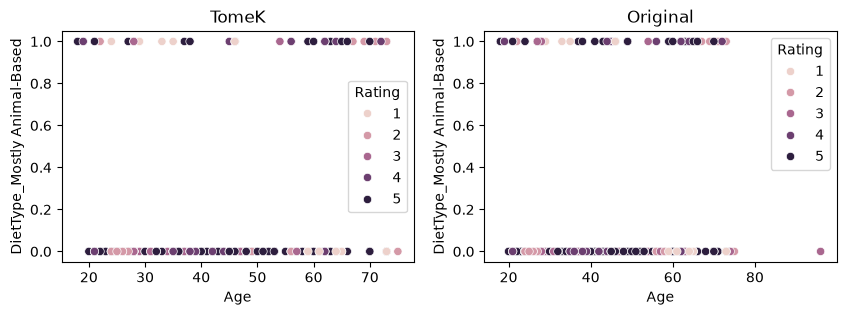

In [54]:
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.scatterplot(df_resampled, x="Age", y='DietType_Mostly Animal-Based', hue="Rating", ax=axes[0])
sns.scatterplot(df, x="Age", y='DietType_Mostly Animal-Based', hue="Rating", ax=axes[1]) 

axes[0].set_title("TomeK")
axes[1].set_title("Original")

# Quite underwhelming... That sort of makes sense though. Tomek is notoriously 
# conservative, even with large amounts of data. Hence why it's commonly used with SMOTE first.

In [55]:
# But let's do a sanity check. How many rows did it get rid of?
print(df.shape)
print(df_resampled.shape)

# It only dropped about 20 rows.

(338, 30)
(287, 30)


---

--- 

### ClusterCentroids

In [56]:
from imblearn.under_sampling import ClusterCentroids

# X y split to prevent data leakage
X = df.drop(columns="Rating", axis=1)
y = df["Rating"]
strategy = {
    1: 20,
    2: 20,
    3: 30,
    4: 30,
    5: 35
}


cc = ClusterCentroids(
    sampling_strategy=strategy,
    random_state=31555
)

X_resampled, y_resampled = cc.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["Rating"] = y_resampled
df_resampled

c:\Users\tuomas.valtanen\dataeng_advda2026_lectures\DataEngineering_AdvDA_2026\.venv\Lib\site-packages\sklearn\base.py:1403: ConvergenceWarning: Number of distinct clusters (16) found smaller than n_clusters (20). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


,Age,LocalFoodFrequency,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,UsingPlasticProducts,...,EnergySource_Non-Renewable,HomeType_Apartment,HomeType_House,Gender_Female,Gender_Male,Gender_Non-Binary,DisposalMethods_Combination,DisposalMethods_Composting,DisposalMethods_Landfill,Rating
0,73,2,2664,1,0,5,0.000000,498,4834,3,...,0,1,0,0,1,0,0,0,1,1
1,35,3,879,0,0,2,1.000000,423,4216,0,...,0,0,1,0,0,0,0,0,1,1
2,21,2,1632,1,1,3,2.000000,191,1399,2,...,1,1,0,1,0,0,1,0,0,1
3,29,0,1876,2,0,1,0.000000,400,4500,3,...,1,0,1,0,1,0,0,0,1,1
4,19,1,1540,3,0,1,2.000000,473,3218,1,...,1,0,1,0,0,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
130,32,0,1850,2,0,1,2.000000,397,4076,1,...,0,0,1,1,0,0,0,0,0,5
131,48,1,2650,2,0,3,1.000000,396,1566,2,...,0,0,0,0,0,1,0,0,0,5
132,38,2,1345,0,1,4,2.000000,123,1234,1,...,0,0,1,1,0,0,0,1,0,5
133,42,2,1868,0,0,3,1.333333,105,1048,0,...,0,0,0,0,0,0,0,0,0,5


Text(0.5, 1.0, 'Original Data')

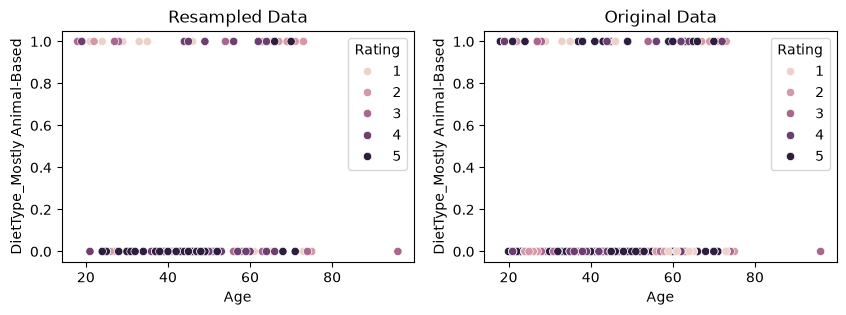

In [57]:
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.scatterplot(df, x="Age", y='DietType_Mostly Animal-Based', hue="Rating", ax=axes[1])    
sns.scatterplot(df_resampled, x="Age", y='DietType_Mostly Animal-Based', hue="Rating", ax=axes[0])
axes[0].set_title("Resampled Data")
axes[1].set_title("Original Data")
# Not bad too, but still a little underwhelming.

In [58]:
# But let's do a sanity check. How many rows did it get rid of?
print(df.shape)
print(df_resampled.shape)

(338, 30)
(135, 30)
